<a href="https://colab.research.google.com/github/ananyamatta1112-crypto/Michelson-Interferometry/blob/main/Michelson_Characterization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

In [ ]:
filename = '/Users/adityamaheshnagare/Downloads/group1sweep.txt'

In [ ]:
data = pd.read_csv(filename, sep='\s+', usecols=[1,2], names=['ch1', 'ch2'], header=None) # for reading dma files
print(data)

             ch1       ch2
0       0.947876 -0.259277
1       0.950195 -0.257202
2       0.952393 -0.255249
3       0.954468 -0.253296
4       0.956543 -0.251099
...          ...       ...
499995  0.764038  1.000000
499996  0.770264  1.000000
499997  0.776978  1.000000
499998  0.784546  1.000000
499999  0.945435 -0.261353

[500000 rows x 2 columns]


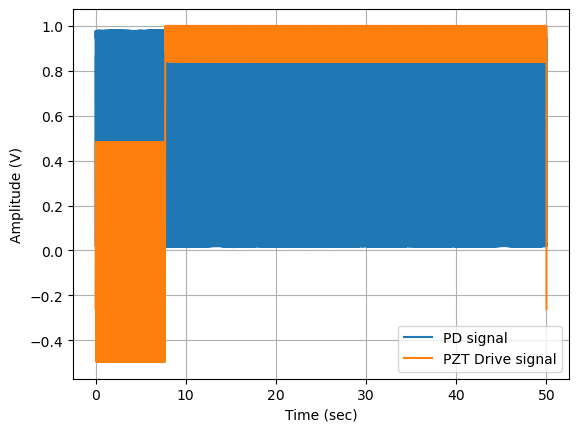

In [ ]:
sample_rate = 10000
tt = np.arange(len(data['ch1'].values))/sample_rate
plt.plot(tt, data['ch1'].values, label='PD signal')
plt.plot(tt, data['ch2'].values, label='PZT Drive signal')
plt.ylabel('Amplitude (V)')
plt.xlabel('Time (sec)')
plt.legend()
plt.grid()

(0.1, 0.13)

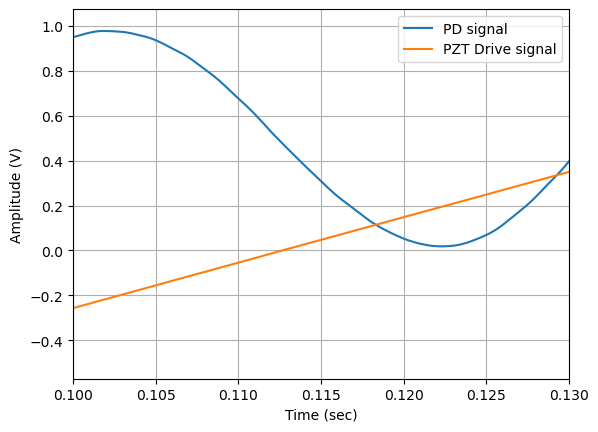

In [ ]:
plt.plot(tt, data['ch1'].values, label='PD signal')
plt.plot(tt, data['ch2'].values, label='PZT Drive signal')
plt.ylabel('Amplitude (V)')
plt.xlabel('Time (sec)')
plt.legend()
plt.grid()
plt.xlim([0.1, 0.13])

(0.1, 0.13)

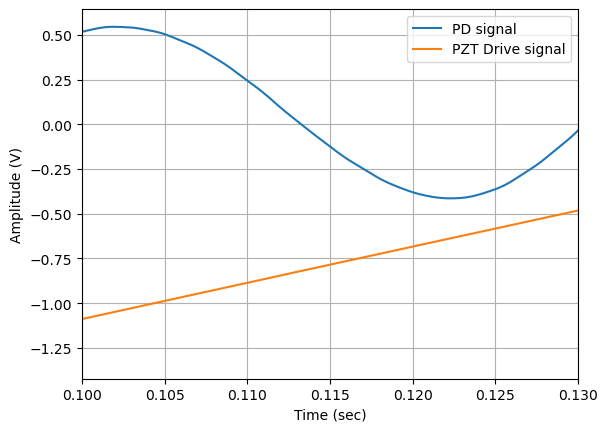

In [ ]:
plt.plot(tt, data['ch1'].values - np.mean(data['ch1'].values) , label='PD signal')
plt.plot(tt, data['ch2'].values - np.mean(data['ch2'].values), label='PZT Drive signal')
plt.ylabel('Amplitude (V)')
plt.xlabel('Time (sec)')
plt.legend()
plt.grid()
plt.xlim([0.1, 0.13])

## Identify max and min indices

In [ ]:
t_ind1 = np.argmin(abs(tt-0.1))
t_ind2 = np.argmin(abs(tt-0.13))
ind_min = np.argmin(data['ch1'].values[t_ind1:t_ind2])+t_ind1
ind_max = np.argmax(data['ch1'].values[t_ind1:t_ind2])+t_ind1

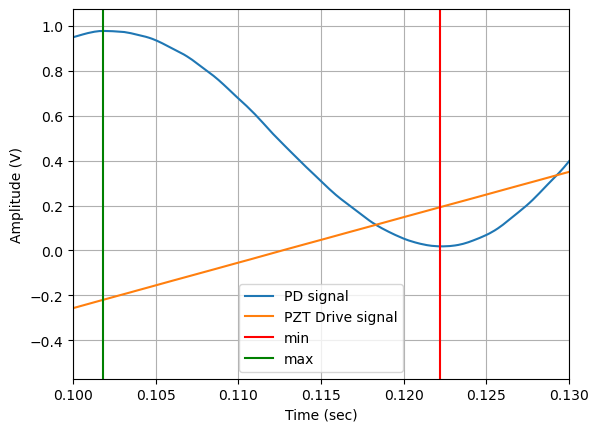

In [ ]:
plt.plot(tt, data['ch1'].values, label='PD signal')
plt.plot(tt, data['ch2'].values, label='PZT Drive signal')
plt.axvline(tt[ind_min], color='r', label='min')
plt.axvline(tt[ind_max], color='g', label='max')
plt.ylabel('Amplitude (V)')
plt.xlabel('Time (sec)')
plt.xlim([tt[t_ind1], tt[t_ind2]])
plt.legend()
plt.grid()

## Fringe Contrast (or) Visibility

In [ ]:
min_value = data['ch1'].values[ind_min]
max_value = data['ch1'].values[ind_max]
contrast = (max_value - min_value)/(max_value + min_value)
operating_point = min_value + (max_value - min_value)/2

print(f"The min_value is {min_value:.4f}")
print(f"The max_value is {max_value:.4f}")
print(f"The fringe contrast is {contrast:.2f} = {contrast*100:.1f}%")
print(f"The operating point is {operating_point:.2f} Volts")

The min_value is 0.0182
The max_value is 0.9775
The fringe contrast is 0.96 = 96.3%
The operating point is 0.50 Volts


## Sensitivity Calibration

In [ ]:
laser_wavelength = 632.8e-9 # He-Ne wavelength
sensitivity = (2*np.pi/laser_wavelength)*(max_value - min_value) # assuming operating at mid-point
print(f"The sensitivity of the IFO is {sensitivity:.2g} V/m")

The sensitivity of the IFO is 9.5e+06 V/m


## Control (PZT drive) Calibration

In [ ]:
V_drive1 = data['ch2'].values[ind_min]
print(V_drive1)
V_drive2 = data['ch2'].values[ind_max]
print(V_drive2)
deltaV = abs(V_drive2 - V_drive1)
drive_calibration = laser_wavelength / (4 * deltaV)
print(f"The calibration of the drive is {drive_calibration:.2g} m/V")

0.192627
-0.220459
The calibration of the drive is 3.8e-07 m/V


# Manufacturer Specifications
# 3.9 $\mu$m$\pm$15% at 150 Volts (Drive Voltage Range 0 - 150 V)
# Hence  2.6e-8 m/V
# Considering Piezo driver gain of 15
# Our Measured value is

In [ ]:
deltaV = abs(V_drive2 - V_drive1)
drive_calibration = laser_wavelength / (4 * deltaV*15)
print(f"The calibration of the drive is {drive_calibration:.2g} m/V")

The calibration of the drive is 2.6e-08 m/V
